# Maldição da Dimensionalidade

Todos os algoritmos da Unidade I dependem de distâncias entre pontos. Em dimensão alta, essas distâncias deixam de discriminar o que está perto do que está longe: é a **maldição da dimensionalidade**. Neste notebook pegamos três grupos bem separados em 2D, acrescentamos dimensões de puro ruído e observamos o K-Means e suas métricas perderem a estrutura, que nunca deixou de estar nos dados.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score

plt.style.use('seaborn-v0_8-whitegrid')
rng = np.random.default_rng(42)
%matplotlib inline

## O Experimento

São 300 pontos em três grupos gaussianos de desvio 1, com centros a 5 unidades uns dos outros. Um conjunto com $d$ dimensões tem sempre as mesmas 2 coordenadas informativas e $d - 2$ coordenadas de ruído gaussiano, **sem nenhuma relação com os grupos**.

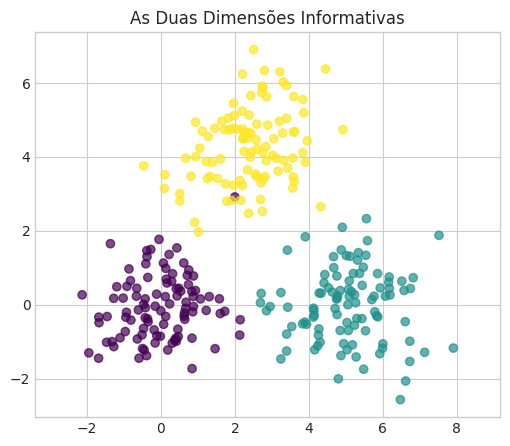

In [2]:
centers = np.array([[0, 0], [5, 0], [2.5, 4.3]])
informative = np.vstack([rng.normal(c, 1, (100, 2)) for c in centers])
y_true = np.repeat([0, 1, 2], 100)
noise = rng.standard_normal((len(y_true), 1000))


def make_data(d):
    return np.hstack([informative, noise[:, :d - 2]])


DIMS = [2, 10, 50, 200, 500, 1000]

plt.figure(figsize=(6, 5))
plt.scatter(informative[:, 0], informative[:, 1], c=y_true, cmap='viridis', alpha=0.7)
plt.title('As Duas Dimensões Informativas')
plt.axis('equal')
plt.show()

## Concentração de Distâncias

A distância ao quadrado soma as contribuições de cada coordenada:

$$ \|\mathbf{x}_i - \mathbf{x}_j\|^2 = \underbrace{\sum_{k=1}^{2} (x_{ik} - x_{jk})^2}_{\text{sinal}} + \underbrace{\sum_{k=3}^{d} (x_{ik} - x_{jk})^2}_{\text{ruído}} $$

O sinal não depende de $d$. O ruído é igual, em média, para qualquer par, mas sua flutuação cresce com $\sqrt{d}$ e acaba maior que toda a diferença produzida pelo sinal.

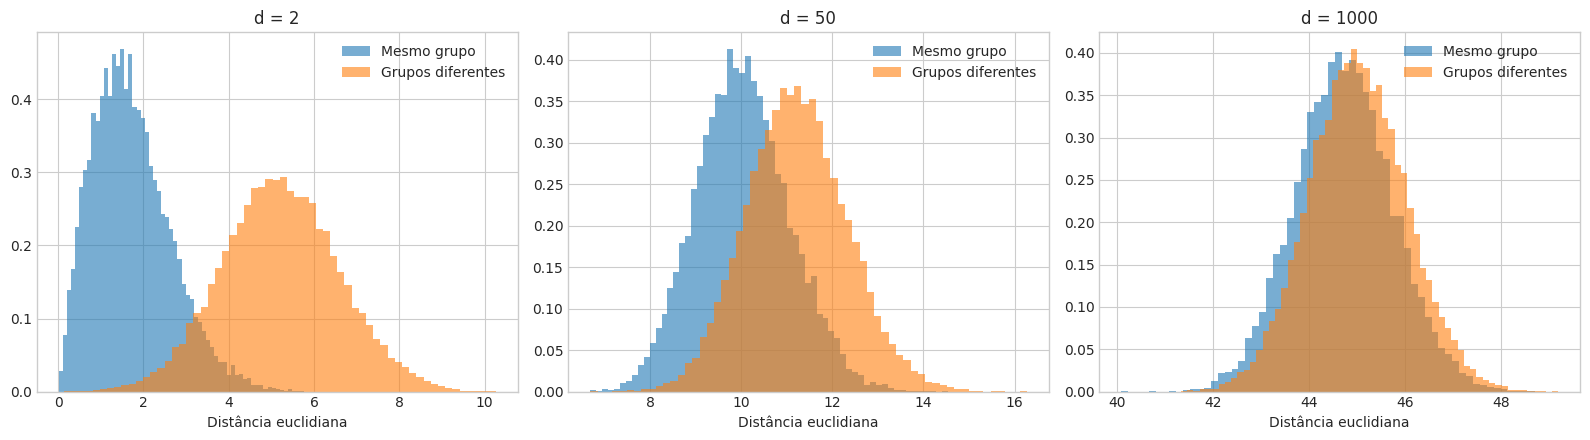

In [3]:
same_cluster = pdist(y_true[:, None]) == 0

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, d in zip(axes, [2, 50, 1000]):
    distances = pdist(make_data(d))
    ax.hist(distances[same_cluster], bins=60, density=True, alpha=0.6, label='Mesmo grupo')
    ax.hist(distances[~same_cluster], bins=60, density=True, alpha=0.6, label='Grupos diferentes')
    ax.set_title(f'd = {d}')
    ax.set_xlabel('Distância euclidiana')
    ax.legend()
plt.tight_layout()
plt.show()

Em 2D as duas distribuições são bem separadas. Em 1000D elas praticamente coincidem: olhando uma distância isolada, é impossível dizer se o par é do mesmo grupo. As distâncias não deixam de existir, deixam de **discriminar**.

## Efeito no K-Means

Medimos o ARI contra os grupos reais e refazemos o Método do Cotovelo em cada dimensão, com a inércia normalizada pela de $K=1$.

d =    2   ARI = 0.970
d =   10   ARI = 0.970
d =   50   ARI = 0.970


d =  200   ARI = 0.941
d =  500   ARI = 0.695


d = 1000   ARI = 0.031


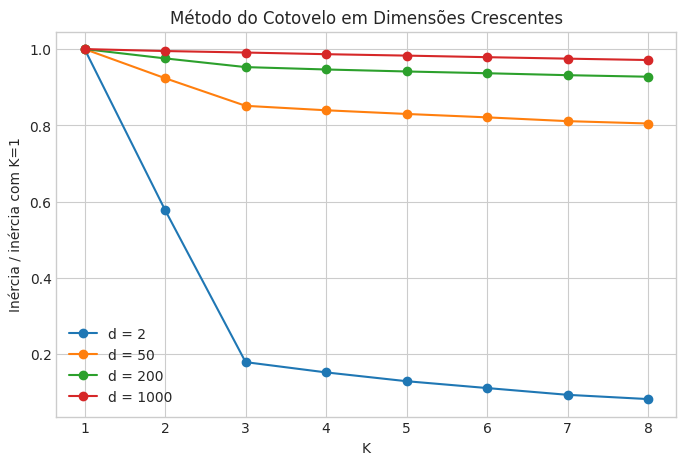

In [4]:
ari = {}
for d in DIMS:
    labels = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(make_data(d))
    ari[d] = adjusted_rand_score(y_true, labels)
    print(f"d = {d:>4}   ARI = {ari[d]:.3f}")

plt.figure(figsize=(8, 5))
for d in [2, 50, 200, 1000]:
    X = make_data(d)
    inertias = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X).inertia_ for k in range(1, 9)]
    plt.plot(range(1, 9), np.array(inertias) / inertias[0], 'o-', label=f'd = {d}')
plt.title('Método do Cotovelo em Dimensões Crescentes')
plt.xlabel('K')
plt.ylabel('Inércia / inércia com K=1')
plt.legend()
plt.show()

O K-Means resiste bastante, porque o centróide é uma **média** de cem pontos e a média cancela parte do ruído, mas em 1000D ele desaba. O cotovelo some bem antes: a inércia passa a ser dominada pelo ruído, que nenhum agrupamento explica, e a curva vira quase uma reta. Mesmo quando o algoritmo ainda acertaria, já não sabemos escolher $K$.

As métricas internas também não avisam. A Silhouette da partição **verdadeira** cai até se confundir com a de uma partição sorteada, porque compara justamente as distâncias que acabaram de ficar iguais.

In [5]:
random_labels = rng.integers(0, 3, len(y_true))
for d in DIMS:
    X = make_data(d)
    print(f"d = {d:>4}   verdadeira = {silhouette_score(X, y_true):.3f}   aleatória = {silhouette_score(X, random_labels):.3f}")

d =    2   verdadeira = 0.623   aleatória = -0.025
d =   10   verdadeira = 0.304   aleatória = -0.011
d =   50   verdadeira = 0.091   aleatória = -0.007
d =  200   verdadeira = 0.025   aleatória = -0.002
d =  500   verdadeira = 0.010   aleatória = -0.001
d = 1000   verdadeira = 0.005   aleatória = -0.001


## O Remédio: Reduzir a Dimensão

A estrutura esteve o tempo todo nas duas primeiras coordenadas; as demais apenas a afogam. Projetando os dados nas 2 direções de maior variância com o PCA, **sem usar os rótulos**, o K-Means volta a funcionar.

In [6]:
for d in DIMS:
    X_proj = PCA(n_components=2).fit_transform(make_data(d))
    labels = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X_proj)
    print(f"d = {d:>4}   K-Means = {ari[d]:.3f}   PCA + K-Means = {adjusted_rand_score(y_true, labels):.3f}")

d =    2   K-Means = 0.970   PCA + K-Means = 0.970
d =   10   K-Means = 0.970   PCA + K-Means = 0.960


d =   50   K-Means = 0.970   PCA + K-Means = 0.960
d =  200   K-Means = 0.941   PCA + K-Means = 0.941


d =  500   K-Means = 0.695   PCA + K-Means = 0.883


d = 1000   K-Means = 0.031   PCA + K-Means = 0.773


O PCA encontra as direções informativas porque é nelas que os dados variam mais: a separação entre os grupos soma variância às duas primeiras coordenadas, enquanto cada coordenada de ruído tem variância 1. É dessa técnica que trata o próximo notebook.

## Exercícios

### Exercício 1: DBSCAN

Repita o experimento com o DBSCAN (`min_samples=15`). Como não há um `eps` óbvio, teste vários valores (por exemplo, quantis da distância de cada ponto ao seu 15º vizinho) e guarde o melhor ARI em cada dimensão. Ele cai antes ou depois do K-Means? Explique a partir do que cada um usa: o centróide é uma média de muitos pontos, a densidade depende apenas dos vizinhos mais próximos.

In [7]:
# Seu código aqui

### Exercício 2: Mais Dados Resolvem?

Fixe $d = 1000$ e gere o experimento com 100, 300, 1000 e 3000 pontos por grupo. O ARI do K-Means melhora? E o do DBSCAN? Relacione com a sua resposta ao Exercício 1.

In [8]:
# Seu código aqui